# Detección temprana de presión arterial elevada con redes neuronales

**Aprendizaje Automático – CUN | ACA 2**
Especialización en Inteligencia Artificial – Escuela de Ingeniería

**Integrantes del grupo:**

- Eyner Adrián Linares Lopez
- Daniel Alejandro Roncancio Rodriguez
- Oscar Mateo Tautiva Rozo
- Karol Ginneth Tautiva Rozo

**Docente:** Hamilton Rivera Flor

**Fecha de entrega:** 15 Noviembre de 2026

## Situación problema y objetivo

**Pregunta orientadora:** ¿puede una red neuronal artificial, entrenada con datos de una encuesta nacional de salud, detectar a tiempo a personas con presión arterial elevada que no saben que la tienen, y ponerse al alcance de cualquier persona en una aplicación web?

**Objetivo general:** desarrollar un modelo de redes neuronales (un perceptrón multicapa profundo y un FT-Transformer) que estime la probabilidad de presión arterial elevada (≥ 130/80 mmHg) a partir de datos demográficos, hábitos y medidas corporales, gestionando los datos en una base SQLite y desplegando el modelo en una aplicación interactiva de Streamlit.

**Dataset:** Encuesta Nacional de Salud y Nutrición de EE. UU. (NHANES 2015-2016, CDC), con 5.735 adultos y 28 variables. Una parte de los datos viene de una entrevista (lo que la persona *dice*) y otra de un examen físico (lo que se *midió*).

### ¿Qué cambia respecto al ACA 1?

| Aspecto | ACA 1 | ACA 2 (este notebook) |
|---|---|---|
| Gestión de datos | CSV leído con pandas | Base de datos **SQLite**: carga, limpieza y consultas en SQL |
| Partición | Entrenamiento / prueba (80/20) | Entrenamiento / **validación** / prueba (70/15/15) |
| Umbral de decisión | Elegido mirando la prueba | Elegido con **validación**; la prueba se usa una sola vez |
| Modelos | Regresión logística y árbol de decisión | **MLP profundo** y **FT-Transformer** (la regresión logística queda como línea base) |
| Aumento de datos | No aplica | Ruido gaussiano en el entrenamiento, con experimento de comparación |
| Evaluación | Métricas finales | Métricas + **curvas de entrenamiento/validación** + intervalos de confianza |
| App | Modelo de sklearn | Pesos de la red en PyTorch + historial de predicciones en SQLite |

### Flujo metodológico

**Paso 1** Exploración y gestión SQL → **Paso 2** Preparación y pipeline → **Paso 3** Modelado neuronal → **Paso 4** Evaluación y métricas → **Paso 5** Despliegue en Streamlit

## Configuración del entorno

El notebook funciona en Google Colab o en un computador local. En Colab, el CSV se lee desde Drive. Todo lo que necesita la app (base de datos, pesos y configuración) se guarda en la carpeta `app_presion/`.

In [115]:
import os, sys, json, copy, shutil, sqlite3, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_CSV = "/content/drive/MyDrive/grafoca3d.csv"
else:
    RUTA_CSV = "grafoca3d.csv"

CARPETA_APP = Path("app_presion")
CARPETA_ART = CARPETA_APP / "artefactos"
CARPETA_ART.mkdir(parents=True, exist_ok=True)
RUTA_DB = CARPETA_APP / "nhanes_presion.db"

print("Colab:", EN_COLAB, "| CSV:", RUTA_CSV, "| Base de datos:", RUTA_DB)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True | CSV: /content/drive/MyDrive/grafoca3d.csv | Base de datos: app_presion/nhanes_presion.db


In [116]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEMILLA)
VERSION_TORCH = torch.__version__
print("PyTorch", VERSION_TORCH)

PyTorch 2.14.1+cpu


---
# 1. Exploración y gestión de datos con SQLite

SQLite es una base de datos que vive en un solo archivo (`nhanes_presion.db`). La usamos para:

1. **Almacenar** los datos crudos en una tabla con esquema y llave primaria.
2. **Documentar** las variables en una tabla de diccionario.
3. **Limpiar** con SQL (vista `v_presion`) y guardar el resultado en la tabla `datos_limpios`.
4. **Consultar** para el análisis exploratorio.
5. **Registrar** métricas, curvas de entrenamiento y las predicciones que haga la app.

### 1.1 Crear la base y la tabla de datos crudos

In [117]:
df_crudo = pd.read_csv(RUTA_CSV)
print("CSV original:", df_crudo.shape)

conexion = sqlite3.connect(RUTA_DB)
cur = conexion.cursor()

cur.executescript("""
DROP TABLE IF EXISTS nhanes_crudo;
CREATE TABLE nhanes_crudo (
    SEQN     INTEGER PRIMARY KEY,                       -- identificador del participante
    ALQ101   REAL, ALQ110 REAL, ALQ130 REAL,            -- alcohol (entrevista)
    SMQ020   INTEGER,                                   -- tabaco (entrevista)
    RIAGENDR INTEGER, RIDAGEYR INTEGER,                 -- sexo y edad
    RIDRETH1 INTEGER, DMDCITZN REAL,                    -- origen y ciudadanía
    DMDEDUC2 REAL, DMDMARTL REAL, DMDHHSIZ INTEGER,     -- educación, estado civil, hogar
    WTINT2YR REAL, SDMVPSU INTEGER, SDMVSTRA INTEGER,   -- diseño muestral de la encuesta
    INDFMPIR REAL,                                      -- ingreso / línea de pobreza
    BPXSY1 REAL, BPXDI1 REAL, BPXSY2 REAL, BPXDI2 REAL, -- presión arterial (examen)
    BMXWT REAL, BMXHT REAL, BMXBMI REAL, BMXLEG REAL,   -- antropometría (examen)
    BMXARML REAL, BMXARMC REAL, BMXWAIST REAL,
    HIQ210   REAL                                       -- seguro médico
);
""")

def a_python(valor):
    """sqlite3 no acepta tipos de numpy ni NaN: se convierten a tipos de Python / NULL."""
    if pd.isna(valor):
        return None
    return valor.item() if hasattr(valor, "item") else valor

columnas = list(df_crudo.columns)
sql_insert = f"INSERT INTO nhanes_crudo ({', '.join(columnas)}) VALUES ({', '.join('?' * len(columnas))})"
filas = [tuple(a_python(v) for v in fila) for fila in df_crudo.itertuples(index=False, name=None)]
cur.executemany(sql_insert, filas)
conexion.commit()

def consulta(sql, params=()):
    """Ejecuta un SELECT y devuelve un DataFrame."""
    return pd.read_sql_query(sql, conexion, params=params)

consulta("SELECT COUNT(*) AS registros, COUNT(DISTINCT SEQN) AS participantes, "
         "MIN(RIDAGEYR) AS edad_min, MAX(RIDAGEYR) AS edad_max FROM nhanes_crudo")

CSV original: (5735, 28)


,registros,participantes,edad_min,edad_max
0,5735,5735,18,80


### 1.2 Diccionario de datos

Las columnas de NHANES tienen nombres en código. Guardamos el diccionario en la propia base, con el origen de cada dato (entrevista o examen) y la decisión que tomamos sobre él.

In [118]:
diccionario = [
    # código,    nombre,                   descripción,                                     origen,       decisión
    ("SEQN",     "id",                     "Identificador del participante",                "Sistema",    "Llave primaria"),
    ("ALQ101",   "alcohol",                "¿Ha tomado 12 o más tragos en un año?",         "Entrevista", "Predictora"),
    ("ALQ110",   "alcohol_vida",           "¿12 o más tragos en toda la vida?",             "Entrevista", "Eliminada: solo se pregunta a algunos"),
    ("ALQ130",   "tragos_dia",             "Tragos promedio por día",                       "Entrevista", "Eliminada: muchos vacíos por diseño"),
    ("SMQ020",   "fuma",                   "¿Ha fumado 100 o más cigarrillos en la vida?",  "Entrevista", "Predictora"),
    ("RIAGENDR", "sexo",                   "Sexo",                                          "Entrevista", "Predictora"),
    ("RIDAGEYR", "edad",                   "Edad en años (tope en 80)",                     "Entrevista", "Predictora"),
    ("RIDRETH1", "origen",                 "Origen étnico",                                 "Entrevista", "Eliminada: no se usa en la app"),
    ("DMDCITZN", "ciudadania",             "Ciudadanía",                                    "Entrevista", "Eliminada: no se usa en la app"),
    ("DMDEDUC2", "educacion",              "Nivel educativo (solo mayores de 20)",          "Entrevista", "Predictora"),
    ("DMDMARTL", "estado_civil",           "Estado civil (solo mayores de 20)",             "Entrevista", "Predictora"),
    ("DMDHHSIZ", "personas_hogar",         "Personas en el hogar (tope en 7)",              "Entrevista", "Predictora"),
    ("WTINT2YR", "peso_muestral",          "Peso muestral de la entrevista",                "Diseño",     "Eliminada: diseño de la encuesta"),
    ("SDMVPSU",  "psu",                    "Unidad primaria de muestreo",                   "Diseño",     "Eliminada: diseño de la encuesta"),
    ("SDMVSTRA", "estrato",                "Estrato de muestreo",                           "Diseño",     "Eliminada: diseño de la encuesta"),
    ("INDFMPIR", "ratio_ingreso_pobreza",  "Ingreso familiar / línea de pobreza (0 a 5)",   "Entrevista", "Predictora"),
    ("BPXSY1",   "sistolica_1",            "Presión sistólica, lectura 1",                  "Examen",     "Solo para crear el objetivo (fuga)"),
    ("BPXDI1",   "diastolica_1",           "Presión diastólica, lectura 1",                 "Examen",     "Solo para crear el objetivo (fuga)"),
    ("BPXSY2",   "sistolica_2",            "Presión sistólica, lectura 2",                  "Examen",     "Solo para crear el objetivo (fuga)"),
    ("BPXDI2",   "diastolica_2",           "Presión diastólica, lectura 2",                 "Examen",     "Solo para crear el objetivo (fuga)"),
    ("BMXWT",    "peso_kg",                "Peso",                                          "Examen",     "Eliminada: redundante con el IMC"),
    ("BMXHT",    "estatura_cm",            "Estatura",                                      "Examen",     "Eliminada: redundante con el IMC"),
    ("BMXBMI",   "imc",                    "Índice de masa corporal",                       "Examen",     "Predictora"),
    ("BMXLEG",   "largo_pierna",           "Largo de la pierna",                            "Examen",     "Eliminada: poco práctica para la app"),
    ("BMXARML",  "largo_brazo",            "Largo del brazo",                               "Examen",     "Eliminada: poco práctica para la app"),
    ("BMXARMC",  "circ_brazo",             "Circunferencia del brazo",                      "Examen",     "Eliminada: poco práctica para la app"),
    ("BMXWAIST", "cintura_cm",             "Circunferencia de la cintura",                  "Examen",     "Predictora"),
    ("HIQ210",   "sin_seguro",             "¿Estuvo sin seguro médico el último año?",      "Entrevista", "Eliminada: muchos vacíos"),
]

cur.executescript("""
DROP TABLE IF EXISTS diccionario;
CREATE TABLE diccionario (
    codigo TEXT PRIMARY KEY, nombre TEXT, descripcion TEXT, origen TEXT, decision TEXT
);
""")
cur.executemany("INSERT INTO diccionario VALUES (?, ?, ?, ?, ?)", diccionario)
conexion.commit()

consulta("SELECT origen, decision, COUNT(*) AS variables FROM diccionario "
         "GROUP BY origen, decision ORDER BY origen, variables DESC")

,origen,decision,variables
0,Diseño,Eliminada: diseño de la encuesta,3
1,Entrevista,Predictora,8
2,Entrevista,Eliminada: no se usa en la app,2
3,Entrevista,Eliminada: solo se pregunta a algunos,1
4,Entrevista,Eliminada: muchos vacíos por diseño,1
5,Entrevista,Eliminada: muchos vacíos,1
6,Examen,Solo para crear el objetivo (fuga),4
7,Examen,Eliminada: poco práctica para la app,3
8,Examen,Predictora,2
9,Examen,Eliminada: redundante con el IMC,2


### 1.3 Códigos que no son datos reales

NHANES usa números especiales para "no sabe" o "no respondió" (7, 9, 77, 99), y una diastólica en 0 significa que no hubo medición. Contamos cuántos hay antes de limpiarlos:

In [119]:
consulta("""
SELECT 'SMQ020 (fuma): 7 o 9'               AS caso, SUM(SMQ020   IN (7, 9))   AS registros FROM nhanes_crudo
UNION ALL SELECT 'ALQ101 (alcohol): 7 o 9',          SUM(ALQ101   IN (7, 9))   FROM nhanes_crudo
UNION ALL SELECT 'DMDEDUC2 (educación): 7 o 9',      SUM(DMDEDUC2 IN (7, 9))   FROM nhanes_crudo
UNION ALL SELECT 'DMDMARTL (estado civil): 77 o 99', SUM(DMDMARTL IN (77, 99)) FROM nhanes_crudo
UNION ALL SELECT 'BPXDI1 = 0 (sin medición)',        SUM(BPXDI1 = 0)           FROM nhanes_crudo
UNION ALL SELECT 'BPXDI2 = 0 (sin medición)',        SUM(BPXDI2 = 0)           FROM nhanes_crudo
UNION ALL SELECT 'Sin ninguna lectura de presión',
                 SUM(BPXSY1 IS NULL AND BPXSY2 IS NULL)                        FROM nhanes_crudo
""")

,caso,registros
0,SMQ020 (fuma): 7 o 9,10
1,ALQ101 (alcohol): 7 o 9,3
2,DMDEDUC2 (educación): 7 o 9,3
3,DMDMARTL (estado civil): 77 o 99,2
4,BPXDI1 = 0 (sin medición),26
5,BPXDI2 = 0 (sin medición),33
6,Sin ninguna lectura de presión,168


### 1.4 Limpieza con SQL: vista `v_presion` y tabla `datos_limpios`

La vista aplica las mismas reglas del ACA 1, ahora en SQL:

- La diastólica en 0 pasa a `NULL` (`NULLIF`).
- La presión se promedia con las lecturas disponibles. Si falta una de las dos, se usa la otra.
- **Variable objetivo:** `presion_elevada = 1` si la sistólica promedio es ≥ 130 **o** la diastólica promedio es ≥ 80 (umbral de la guía AHA/ACC 2017).
- Los códigos se traducen a etiquetas en español con `CASE`. Cualquier código que no esté en la lista (7, 9, 77…) queda en `NULL`.
- A los menores de 20 años no se les preguntó educación ni estado civil, así que reciben la categoría "No aplica (menor de 20)".
- Las lecturas de presión **no** pasan a la tabla limpia, porque son la respuesta (fuga de datos).

In [120]:
cur.executescript("""
DROP VIEW IF EXISTS v_presion;
CREATE VIEW v_presion AS
--Crea una tabla temporal en memoria donde cualquier diastólica igual a 0 se transforma automáticamente en NULL mediante NULLIF
WITH medidas AS (
    SELECT *, NULLIF(BPXDI1, 0) AS di1, NULLIF(BPXDI2, 0) AS di2
    FROM nhanes_crudo
),
-- Calcula el promedio de las dos lecturas sistólicas y diastólicas
promedios AS (
    SELECT *,
        (COALESCE(BPXSY1, 0) + COALESCE(BPXSY2, 0)) * 1.0
            / NULLIF((BPXSY1 IS NOT NULL) + (BPXSY2 IS NOT NULL), 0) AS sist_prom,
        (COALESCE(di1, 0) + COALESCE(di2, 0)) * 1.0
            / NULLIF((di1 IS NOT NULL) + (di2 IS NOT NULL), 0)       AS diast_prom
    FROM medidas
)
-- Convertimos los códigos numéricos en texto legible. Al no poner un ELSE, cualquier otro número (7, 9) se convierte automáticamente en NULL
SELECT
    SEQN,
    CASE ALQ101   WHEN 1 THEN 'Sí' WHEN 2 THEN 'No' END                     AS alcohol,
    CASE SMQ020   WHEN 1 THEN 'Sí' WHEN 2 THEN 'No' END                     AS fuma,
    CASE RIAGENDR WHEN 1 THEN 'Hombre' WHEN 2 THEN 'Mujer' END              AS sexo,
    RIDAGEYR                                                                AS edad,
    COALESCE(
        CASE DMDEDUC2 WHEN 1 THEN 'Menos de 9.º grado' WHEN 2 THEN '9.º a 11.º grado'
                      WHEN 3 THEN 'Bachiller'          WHEN 4 THEN 'Técnico o universidad incompleta'
                      WHEN 5 THEN 'Universitario o más' END,
        CASE WHEN RIDAGEYR < 20 THEN 'No aplica (menor de 20)' END)       AS educacion,
    COALESCE(
        CASE DMDMARTL WHEN 1 THEN 'Casado(a)'    WHEN 2 THEN 'Viudo(a)'  WHEN 3 THEN 'Divorciado(a)'
                      WHEN 4 THEN 'Separado(a)'  WHEN 5 THEN 'Soltero(a)' WHEN 6 THEN 'Unión libre' END,
        CASE WHEN RIDAGEYR < 20 THEN 'No aplica (menor de 20)' END)       AS estado_civil,
    DMDHHSIZ                                                                AS personas_hogar,
    INDFMPIR                                                                AS ratio_ingreso_pobreza,
    BMXBMI                                                                  AS imc,
    BMXWAIST                                                                AS cintura_cm,
    CASE WHEN sist_prom >= 130 OR diast_prom >= 80 THEN 1 ELSE 0 END        AS presion_elevada
FROM promedios
WHERE sist_prom IS NOT NULL AND diast_prom IS NOT NULL;

DROP TABLE IF EXISTS datos_limpios;
CREATE TABLE datos_limpios AS SELECT * FROM v_presion;
CREATE UNIQUE INDEX idx_limpios_seqn ON datos_limpios (SEQN);
""")
conexion.commit()

consulta("""
SELECT (SELECT COUNT(*) FROM nhanes_crudo)                   AS registros_crudos,
       COUNT(*)                                              AS registros_limpios,
       (SELECT COUNT(*) FROM nhanes_crudo) - COUNT(*)        AS descartados_sin_presion,
       ROUND(AVG(presion_elevada), 3)                        AS proporcion_elevada
FROM datos_limpios
""")

,registros_crudos,registros_limpios,descartados_sin_presion,proporcion_elevada
0,5735,5550,185,0.399


### 1.5 Validación: ¿el SQL da exactamente lo mismo que la limpieza del ACA 1?

Repetimos la limpieza del ACA 1 con pandas y la comparamos fila por fila con la tabla de SQL. Si la prueba pasa, el cambio de herramienta no alteró los datos. En el ACA 1 se obtuvieron 5.550 registros y un 39,9 % de presión elevada.

In [121]:
def limpieza_aca1(df):
    d = df.copy()
    for c in ["BPXDI1", "BPXDI2"]:
        d.loc[d[c] == 0, c] = np.nan
    d["sist_prom"] = d[["BPXSY1", "BPXSY2"]].mean(axis=1)
    d["diast_prom"] = d[["BPXDI1", "BPXDI2"]].mean(axis=1)
    d = d.dropna(subset=["sist_prom", "diast_prom"])
    d["presion_elevada"] = ((d["sist_prom"] >= 130) | (d["diast_prom"] >= 80)).astype(int)
    d = d.rename(columns={"RIDAGEYR": "edad", "RIAGENDR": "sexo", "BMXBMI": "imc", "BMXWAIST": "cintura_cm",
                          "INDFMPIR": "ratio_ingreso_pobreza", "DMDHHSIZ": "personas_hogar", "SMQ020": "fuma",
                          "ALQ101": "alcohol", "DMDEDUC2": "educacion", "DMDMARTL": "estado_civil"})
    etiquetas = {
        "sexo": {1: "Hombre", 2: "Mujer"}, "fuma": {1: "Sí", 2: "No"}, "alcohol": {1: "Sí", 2: "No"},
        "educacion": {1: "Menos de 9.º grado", 2: "9.º a 11.º grado", 3: "Bachiller",
                      4: "Técnico o universidad incompleta", 5: "Universitario o más"},
        "estado_civil": {1: "Casado(a)", 2: "Viudo(a)", 3: "Divorciado(a)",
                         4: "Separado(a)", 5: "Soltero(a)", 6: "Unión libre"},
    }
    for col, mapa in etiquetas.items():
        d[col] = d[col].map(mapa)
    for col in ["educacion", "estado_civil"]:
        d.loc[(d["edad"] < 20) & d[col].isna(), col] = "No aplica (menor de 20)"
    return d

columnas_finales = ["alcohol", "fuma", "sexo", "edad", "educacion", "estado_civil", "personas_hogar",
                    "ratio_ingreso_pobreza", "imc", "cintura_cm", "presion_elevada"]
con_pandas = limpieza_aca1(df_crudo).set_index("SEQN")[columnas_finales].sort_index()
con_sql = consulta("SELECT * FROM datos_limpios").set_index("SEQN")[columnas_finales].sort_index()

pd.testing.assert_frame_equal(con_pandas, con_sql, check_dtype=False)
print(f"✅ SQL y pandas coinciden: {len(con_sql)} registros, "
      f"{con_sql['presion_elevada'].mean():.1%} con presión elevada.")

✅ SQL y pandas coinciden: 5550 registros, 39.9% con presión elevada.


/tmp/ipykernel_567/3784005660.py:30: FutureWarning: Mismatched null-like values nan and None found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(con_pandas, con_sql, check_dtype=False)


### 1.6 Análisis exploratorio con consultas SQL

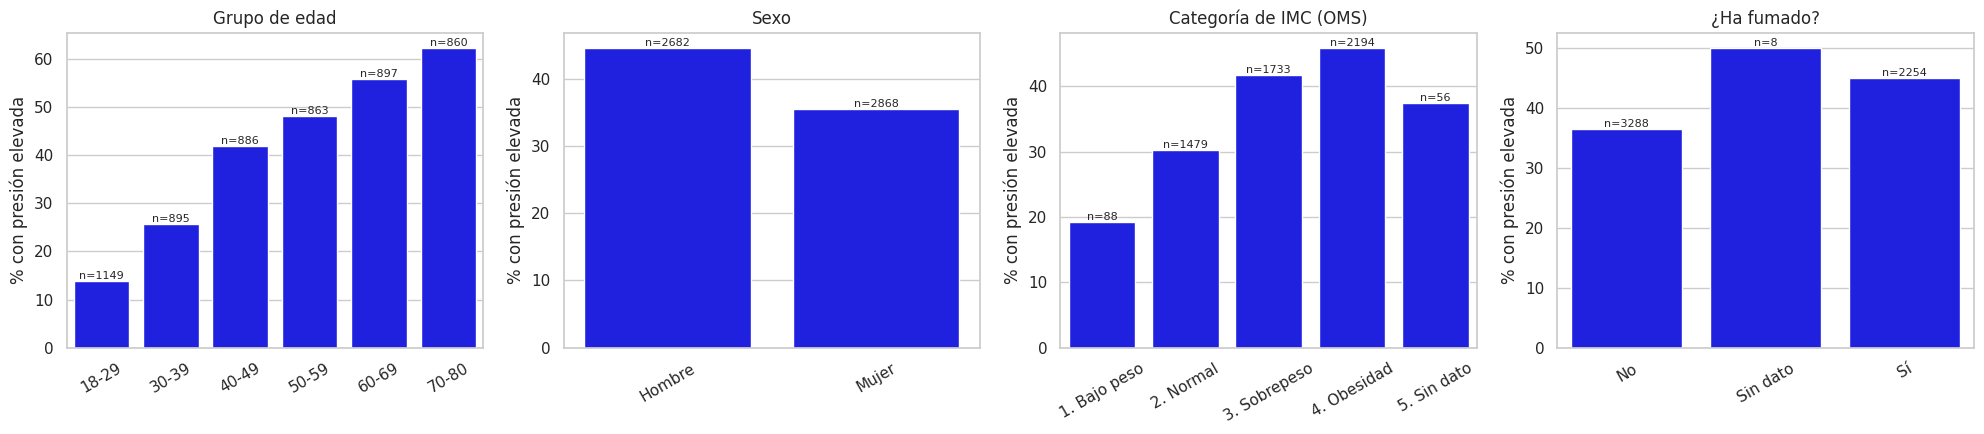

,grupo,personas,pct_elevada
0,18-29,1149,13.8
1,30-39,895,25.8
2,40-49,886,41.9
3,50-59,863,48.2
4,60-69,897,55.9
5,70-80,860,62.4


In [122]:
# agrupamos deacuerdo a la edad, sexo, imc y fuma; contamos personas, calculamos porcentaje de presión elevada

sql_edad = """
SELECT CASE WHEN edad < 30 THEN '18-29' WHEN edad < 40 THEN '30-39' WHEN edad < 50 THEN '40-49'
            WHEN edad < 60 THEN '50-59' WHEN edad < 70 THEN '60-69' ELSE '70-80' END AS grupo,
       COUNT(*) AS personas, ROUND(100.0 * AVG(presion_elevada), 1) AS pct_elevada
FROM datos_limpios GROUP BY grupo ORDER BY grupo
"""
sql_sexo = """
SELECT sexo AS grupo, COUNT(*) AS personas, ROUND(100.0 * AVG(presion_elevada), 1) AS pct_elevada
FROM datos_limpios GROUP BY sexo
"""

# Clasificación del imc según OMS

sql_imc = """
SELECT CASE WHEN imc IS NULL THEN '5. Sin dato' WHEN imc < 18.5 THEN '1. Bajo peso'
            WHEN imc < 25 THEN '2. Normal' WHEN imc < 30 THEN '3. Sobrepeso' ELSE '4. Obesidad' END AS grupo,
       COUNT(*) AS personas, ROUND(100.0 * AVG(presion_elevada), 1) AS pct_elevada
FROM datos_limpios GROUP BY grupo ORDER BY grupo
"""
sql_fuma = """
SELECT COALESCE(fuma, 'Sin dato') AS grupo, COUNT(*) AS personas,
       ROUND(100.0 * AVG(presion_elevada), 1) AS pct_elevada
FROM datos_limpios GROUP BY grupo
"""

tablas_eda = {"Grupo de edad": consulta(sql_edad), "Sexo": consulta(sql_sexo),
              "Categoría de IMC (OMS)": consulta(sql_imc), "¿Ha fumado?": consulta(sql_fuma)}

fig, ejes = plt.subplots(1, 4, figsize=(20, 4.5))
for eje, (titulo, tabla) in zip(ejes, tablas_eda.items()):
    sns.barplot(data=tabla, x="grupo", y="pct_elevada", ax=eje, color="blue")
    eje.set_title(titulo); eje.set_xlabel(""); eje.set_ylabel("% con presión elevada")
    eje.tick_params(axis="x", rotation=30)
    for barra, n in zip(eje.patches, tabla["personas"]):
        eje.annotate(f"n={n}", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                     ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig(CARPETA_ART / "eda_prevalencia.png", dpi=150, bbox_inches="tight")
plt.show()

tablas_eda["Grupo de edad"]

In [123]:
# Valores faltantes por variable, calculados con SQL
variables_limpias = [c for c in consulta("SELECT * FROM datos_limpios LIMIT 1").columns if c != "SEQN"]
sql_nulos = "\nUNION ALL ".join(
    f"SELECT '{c}' AS variable, SUM({c} IS NULL) AS nulos, "
    f"ROUND(100.0 * SUM({c} IS NULL) / COUNT(*), 1) AS pct FROM datos_limpios"
    for c in variables_limpias)
consulta(sql_nulos).sort_values("nulos", ascending=False)

,variable,nulos,pct
7,ratio_ingreso_pobreza,571,10.3
0,alcohol,443,8.0
9,cintura_cm,296,5.3
8,imc,56,1.0
1,fuma,8,0.1
5,estado_civil,2,0.0
4,educacion,2,0.0
2,sexo,0,0.0
3,edad,0,0.0
6,personas_hogar,0,0.0


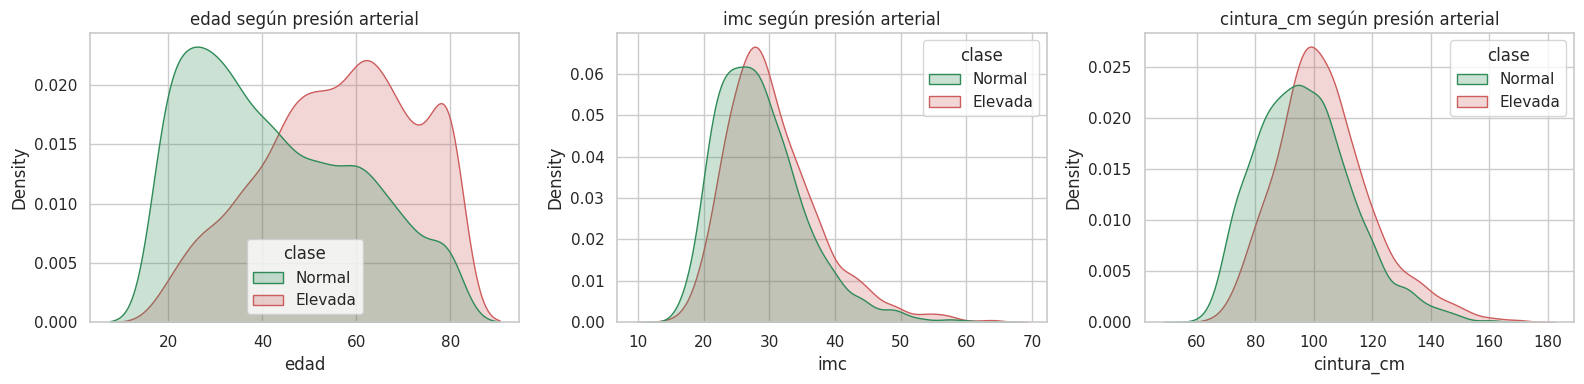

In [124]:
# Distribución de las variables numéricas más relevantes según la clase
datos_eda = consulta("SELECT edad, imc, cintura_cm, presion_elevada FROM datos_limpios")
datos_eda["clase"] = datos_eda["presion_elevada"].map({0: "Normal", 1: "Elevada"})

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for eje, col in zip(ejes, ["edad", "imc", "cintura_cm"]):
    sns.kdeplot(data=datos_eda, x=col, hue="clase", fill=True, common_norm=False, ax=eje,
                palette={"Normal": "seagreen", "Elevada": "indianred"})
    eje.set_title(f"{col} según presión arterial")
plt.tight_layout()
plt.show()

**Lectura del EDA:**

- **La edad es el factor más fuerte.** El porcentaje de presión elevada sube sin excepción en cada grupo de edad: pasa del 13,8 % entre los 18 y 29 años al 62,4 % entre los 70 y 80. Es decir, una persona mayor de 70 tiene unas 4,5 veces más probabilidad que un adulto joven.
- **Sexo:** los hombres tienen más presión elevada que las mujeres (cerca del 45 % frente al 35 %).
- **Obesidad:** el porcentaje aumenta con la categoría de IMC: alrededor del 19 % en bajo peso, 30 % en peso normal, 41 % en sobrepeso y 46 % en obesidad. Las curvas de densidad muestran lo mismo con la cintura: las personas con presión elevada se concentran en cinturas más grandes.
- **Tabaco:** quienes han fumado muestran más presión elevada (cerca del 45 % frente al 36 %). Sin embargo, como se verá en la sección 4.5, este efecto desaparece cuando el modelo considera las demás variables. Una explicación probable es que los fumadores de la muestra tienden a ser mayores.
- **Datos faltantes:** el ingreso (10,3 %), el alcohol (8 %) y la cintura (5,3 %) son las variables con más vacíos. Por eso se imputan dentro del pipeline, después de dividir los datos.

En resumen, el riesgo se concentra en la edad, el sexo masculino y las medidas de obesidad (IMC y cintura). Estos dos últimos son factores que se pueden modificar con alimentación y actividad física.

---
# 2. Preparación y pipeline

### 2.1 Lectura y partición en tres conjuntos



In [125]:
from sklearn.model_selection import train_test_split

NUMERICAS = ["edad", "imc", "cintura_cm", "ratio_ingreso_pobreza", "personas_hogar"]
CATEGORICAS = ["sexo", "fuma", "alcohol", "educacion", "estado_civil"]
VARIABLES = NUMERICAS + CATEGORICAS

datos = consulta("SELECT * FROM datos_limpios").set_index("SEQN")
# sqlite devuelve los vacíos de texto como None; sklearn espera np.nan
datos[CATEGORICAS] = datos[CATEGORICAS].astype(object).where(datos[CATEGORICAS].notna(), np.nan)

X, y = datos[VARIABLES], datos["presion_elevada"].astype(int)

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEMILLA)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=SEMILLA)

for nombre, yy in [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]:
    print(f"{nombre:<14} {len(yy):>5} registros | {yy.mean():.1%} con presión elevada")

particiones = pd.concat([pd.DataFrame({"SEQN": idx.index, "conjunto": nombre})
                         for nombre, idx in [("train", X_train), ("val", X_val), ("test", X_test)]])
_ = particiones.to_sql("particiones", conexion, if_exists="replace", index=False)

Entrenamiento   3884 registros | 39.9% con presión elevada
Validación       833 registros | 40.0% con presión elevada
Prueba           833 registros | 39.9% con presión elevada


### 2.2 Preprocesamiento para la red neuronal

- **Numéricas:** se estandarizan (media 0, desviación 1), porque las redes neuronales convergen mejor con entradas en la misma escala. Luego los vacíos se imputan con los 5 vecinos más parecidos (KNN).
- **Categóricas:** los vacíos pasan a la categoría "No responde" y cada categoría se convierte en un número entero. La red aprende un **embedding** para cada categoría, es decir, un vector que la representa. Es la forma estándar de alimentar categorías a una red. El índice 0 queda reservado para categorías nunca vistas.
- El preprocesador se ajusta **solo con entrenamiento** para evitar fuga de datos.

In [126]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

def pipeline_numerico():
    return Pipeline([("escalar", StandardScaler()), ("imputar", KNNImputer(n_neighbors=5))])

prep_nn = ColumnTransformer([
    ("num", pipeline_numerico(), NUMERICAS),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="No responde")),
        ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ]), CATEGORICAS),
], verbose_feature_names_out=False)

Z_train = prep_nn.fit_transform(X_train)
Z_val, Z_test = prep_nn.transform(X_val), prep_nn.transform(X_test)

categorias = {col: list(cats) for col, cats in
              zip(CATEGORICAS, prep_nn.named_transformers_["cat"].named_steps["ordinal"].categories_)}
cardinalidades = [len(c) + 1 for c in categorias.values()]   # +1: índice 0 = desconocida

print("Forma después del preprocesamiento:", Z_train.shape, "| nulos:", int(np.isnan(Z_train).sum()))
for col, cats in categorias.items():
    print(f"  {col:<13} {len(cats)} categorías: {cats}")

Forma después del preprocesamiento: (3884, 10) | nulos: 0
  sexo          2 categorías: ['Hombre', 'Mujer']
  fuma          3 categorías: ['No', 'No responde', 'Sí']
  alcohol       3 categorías: ['No', 'No responde', 'Sí']
  educacion     7 categorías: ['9.º a 11.º grado', 'Bachiller', 'Menos de 9.º grado', 'No aplica (menor de 20)', 'No responde', 'Técnico o universidad incompleta', 'Universitario o más']
  estado_civil  8 categorías: ['Casado(a)', 'Divorciado(a)', 'No aplica (menor de 20)', 'No responde', 'Separado(a)', 'Soltero(a)', 'Unión libre', 'Viudo(a)']


### 2.3 Aumento de datos

En imágenes el aumento de datos consiste en rotar o recortar. En datos tabulares, una técnica equivalente es agregar **ruido gaussiano pequeño** (σ = 0,05 desviaciones estándar) a las variables numéricas de cada lote de entrenamiento. Así la red nunca ve dos veces exactamente la misma persona. Esto actúa como regularización y simula el error normal de medición: una cinta métrica no da el mismo valor dos veces.

- Se aplica **solo en entrenamiento**, nunca en validación ni prueba.
- No se usa SMOTE porque el desbalance es moderado (≈ 40/60). En su lugar se pondera la pérdida con `pos_weight`.
- En el Paso 3 se entrena la misma red **con y sin aumento** para medir si realmente ayuda.

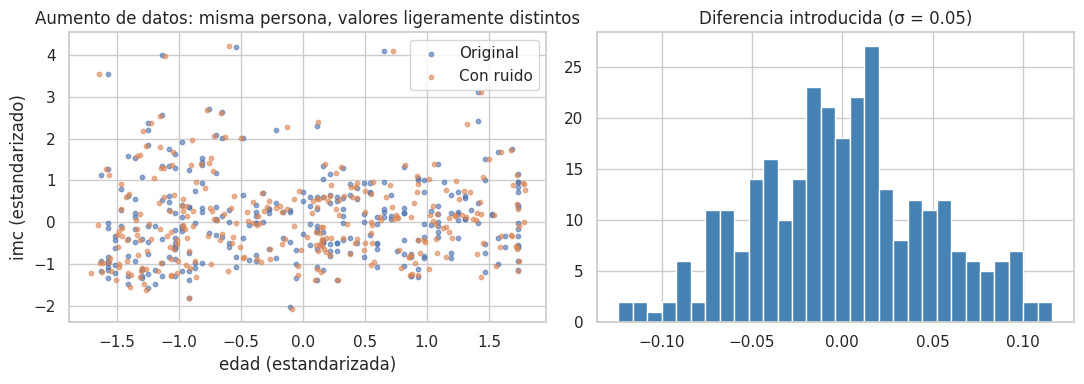

In [127]:
RUIDO = 0.05
rng_demo = np.random.default_rng(SEMILLA)
muestra = Z_train[:300, :len(NUMERICAS)]
aumentada = muestra + RUIDO * rng_demo.standard_normal(muestra.shape)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].scatter(muestra[:, 0], muestra[:, 1], s=10, alpha=0.6, label="Original")
ejes[0].scatter(aumentada[:, 0], aumentada[:, 1], s=10, alpha=0.6, label="Con ruido")
ejes[0].set_xlabel("edad (estandarizada)"); ejes[0].set_ylabel("imc (estandarizado)")
ejes[0].set_title("Aumento de datos: misma persona, valores ligeramente distintos"); ejes[0].legend()
ejes[1].hist(aumentada[:, 0] - muestra[:, 0], bins=30, color="steelblue")
ejes[1].set_title(f"Diferencia introducida (σ = {RUIDO})")
plt.tight_layout(); plt.show()

---
# 3. Modelado con redes neuronales

### 3.1 Arquitecturas

Las arquitecturas se escriben en el archivo `modelos_nn.py`, que **también usa la app de Streamlit**. Así el notebook y la app construyen exactamente la misma red.

**A. MLP profundo con embeddings.** Las 5 variables numéricas y los embeddings de las 5 categóricas se concatenan y pasan por capas densas `Linear → BatchNorm → ReLU → Dropout`, con una neurona de salida (logit).
- *BatchNorm* estabiliza el entrenamiento.
- *Dropout* apaga neuronas al azar para evitar que la red memorice.
- Es la arquitectura de referencia para datos tabulares.

**B. FT-Transformer** (Gorishniy et al., 2021). Cada variable se convierte en un *token* (un vector de 32 dimensiones), como si fuera una palabra en una frase. Se agrega un token especial `[CLS]` y un encoder Transformer con **autoatención multicabeza** permite que cada variable "mire" a las demás. Así aprende interacciones, por ejemplo que la cintura pesa distinto según la edad o el sexo. La predicción sale del token `[CLS]`. Es la adaptación de la arquitectura Transformer (la misma de BERT) a datos tabulares.

**Por qué no CNN ni RNN:** una CNN supone estructura espacial (píxeles vecinos) y una RNN supone orden temporal. Nuestros datos son una fila por persona, sin orden entre columnas. El MLP y el Transformer tabular son las arquitecturas adecuadas para este tipo de dato.



In [128]:
%%writefile modelos_nn.py
"""modelos_nn.py - Arquitecturas neuronales y predictor del proyecto."""
import json
from pathlib import Path

import joblib
import numpy as np
import torch
import torch.nn as nn

NUMERICAS = ["edad", "imc", "cintura_cm", "ratio_ingreso_pobreza", "personas_hogar"]
CATEGORICAS = ["sexo", "fuma", "alcohol", "educacion", "estado_civil"]
VARIABLES = NUMERICAS + CATEGORICAS

# 1. MLP profundo con embeddings para las variables categóricas

class MLPTabular(nn.Module):
    """Perceptrón multicapa: [numéricas + embeddings] -> capas densas -> 1 logit."""

    def __init__(self, n_num, cardinalidades, emb_dim=4, capas=(64, 32, 16), dropout=0.2):
        super().__init__()
        self.embs = nn.ModuleList(
            [nn.Embedding(c, min(emb_dim, c)) for c in cardinalidades]
        )
        d_in = n_num + sum(e.embedding_dim for e in self.embs)
        bloques, previo = [], d_in
        for h in capas:
            bloques += [nn.Linear(previo, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            previo = h
        bloques.append(nn.Linear(previo, 1))
        self.red = nn.Sequential(*bloques)

    def forward(self, x_num, x_cat):
        partes = [x_num] + [emb(x_cat[:, i]) for i, emb in enumerate(self.embs)]
        return self.red(torch.cat(partes, dim=1)).squeeze(1)


# 2. FT-Transformer (Gorishniy): cada variable se vuelve un token

class TokenizadorNumerico(nn.Module):
    """Convierte cada variable numérica x_j en un vector: x_j * w_j + b_j."""

    def __init__(self, n_num, d):
        super().__init__()
        self.w = nn.Parameter(torch.empty(n_num, d))
        self.b = nn.Parameter(torch.zeros(n_num, d))
        nn.init.normal_(self.w, std=0.02)

    def forward(self, x_num):
        return x_num.unsqueeze(-1) * self.w + self.b


class FTTransformer(nn.Module):
    """Tokens de variables + token [CLS] -> encoder Transformer -> 1 logit."""

    def __init__(self, n_num, cardinalidades, d=32, capas=2, cabezas=4, dropout=0.1):
        super().__init__()
        self.num_tok = TokenizadorNumerico(n_num, d)
        self.cat_embs = nn.ModuleList([nn.Embedding(c, d) for c in cardinalidades])
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        nn.init.normal_(self.cls, std=0.02)
        capa = nn.TransformerEncoderLayer(
            d_model=d, nhead=cabezas, dim_feedforward=2 * d,
            dropout=dropout, batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(capa, num_layers=capas, enable_nested_tensor=False)
        self.cabeza = nn.Sequential(nn.LayerNorm(d), nn.ReLU(), nn.Linear(d, 1))

    def forward(self, x_num, x_cat):
        tokens = [self.num_tok(x_num)] + [
            emb(x_cat[:, i]).unsqueeze(1) for i, emb in enumerate(self.cat_embs)
        ]
        x = torch.cat(tokens, dim=1)
        cls = self.cls.expand(x.size(0), -1, -1)
        x = self.encoder(torch.cat([cls, x], dim=1))
        return self.cabeza(x[:, 0]).squeeze(1)


ARQUITECTURAS = {"mlp": MLPTabular, "ft": FTTransformer}


def construir_modelo(tipo, n_num, cardinalidades, hiper):
    return ARQUITECTURAS[tipo](n_num, cardinalidades, **hiper)



# 3. Preprocesamiento -> tensores

def a_tensores(Z, n_num=len(NUMERICAS)):
    """Salida del ColumnTransformer -> (x_num float32, x_cat int64)."""

    Z = np.asarray(Z, dtype=np.float32)
    x_num = torch.tensor(Z[:, :n_num], dtype=torch.float32)
    x_cat = torch.tensor(Z[:, n_num:] + 1, dtype=torch.int64)
    return x_num, x_cat


class PredictorPresion:
    """Une preprocesador + red + umbral. Recibe un DataFrame con VARIABLES."""

    def __init__(self, preprocesador, modelo, umbral, nombre=""):
        self.prep = preprocesador
        self.modelo = modelo.eval()
        self.umbral = float(umbral)
        self.nombre = nombre

    @torch.no_grad()
    def predict_proba(self, df):
        x_num, x_cat = a_tensores(self.prep.transform(df[VARIABLES]))
        return torch.sigmoid(self.modelo(x_num, x_cat)).numpy()

    def predict(self, df):
        return (self.predict_proba(df) >= self.umbral).astype(int)


def cargar_predictores(carpeta):
    """Lee artefactos/config.json y devuelve {nombre: PredictorPresion}."""
    carpeta = Path(carpeta)
    config = json.loads((carpeta / "config.json").read_text(encoding="utf-8"))
    prep = joblib.load(carpeta / config["preprocesador"])
    predictores = {}
    for nombre, m in config["modelos"].items():
        red = construir_modelo(m["tipo"], len(NUMERICAS), config["cardinalidades"], m["hiper"])
        red.load_state_dict(torch.load(carpeta / m["archivo"], map_location="cpu"))
        predictores[nombre] = PredictorPresion(prep, red, m["umbral"], nombre)
    return predictores, config

Overwriting modelos_nn.py


In [129]:
import importlib
import modelos_nn
importlib.reload(modelos_nn)
from modelos_nn import MLPTabular, FTTransformer, PredictorPresion, construir_modelo, a_tensores

tensores = {
    "train": (*a_tensores(Z_train), torch.tensor(y_train.values, dtype=torch.float32)),
    "val":   (*a_tensores(Z_val),   torch.tensor(y_val.values,   dtype=torch.float32)),
    "test":  (*a_tensores(Z_test),  torch.tensor(y_test.values,  dtype=torch.float32)),
}
print({k: tuple(t.shape for t in v) for k, v in tensores.items()})

{'train': (torch.Size([3884, 5]), torch.Size([3884, 5]), torch.Size([3884])), 'val': (torch.Size([833, 5]), torch.Size([833, 5]), torch.Size([833])), 'test': (torch.Size([833, 5]), torch.Size([833, 5]), torch.Size([833]))}


### 3.2 Línea base: regresión logística

In [130]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

prep_lr = ColumnTransformer([
    ("num", pipeline_numerico(), NUMERICAS),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="No responde")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAS),
])
busqueda_lr = GridSearchCV(
    Pipeline([("prep", prep_lr), ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    {"modelo__C": [0.01, 0.1, 1, 10]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA), scoring="roc_auc", n_jobs=-1)
busqueda_lr.fit(X_train, y_train)
modelo_lr = busqueda_lr.best_estimator_
print("Mejor C:", busqueda_lr.best_params_, "| AUC validación cruzada:", round(busqueda_lr.best_score_, 3))

NOMBRE_LR = "Regresión logística"
probabilidades = {NOMBRE_LR: {"val": modelo_lr.predict_proba(X_val)[:, 1],
                              "test": modelo_lr.predict_proba(X_test)[:, 1]}}
historiales, mejores_epocas, configuraciones = {}, {}, {}

Mejor C: {'modelo__C': 0.01} | AUC validación cruzada: 0.726


### 3.3 Función de entrenamiento

- **Pérdida:** entropía cruzada binaria (`BCEWithLogitsLoss`) con `pos_weight` = casos normales / casos elevados, para compensar el desbalance de clases.
- **Optimizador:** AdamW (Adam con *weight decay*, que penaliza pesos grandes).
- **ReduceLROnPlateau:** reduce la tasa de aprendizaje a la mitad cuando la pérdida de validación deja de mejorar.
- **Early stopping:** si la pérdida de validación no mejora en 25 épocas, se detiene y se recuperan los pesos de la mejor época.
- En cada época se registran pérdida, exactitud y AUC en entrenamiento y validación, para las curvas de aprendizaje.

In [131]:
from sklearn.metrics import roc_auc_score

def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

@torch.no_grad()
def evaluar_conjunto(modelo, datos_t, criterio):
    modelo.eval()
    x_num, x_cat, yy = datos_t
    logits = modelo(x_num, x_cat)
    prob = torch.sigmoid(logits).numpy()
    return {"loss": criterio(logits, yy).item(),
            "acc": float(((prob >= 0.5) == yy.numpy()).mean()),
            "auc": roc_auc_score(yy.numpy(), prob)}

def entrenar(modelo, epocas=300, lr=1e-3, weight_decay=1e-4, batch=128, paciencia=25, ruido=0.0):
    x_num, x_cat, yy = tensores["train"]
    generador = torch.Generator().manual_seed(SEMILLA)
    cargador = DataLoader(TensorDataset(x_num, x_cat, yy), batch_size=batch, shuffle=True,
                          drop_last=True, generator=generador)
    pos_weight = ((yy == 0).sum() / (yy == 1).sum()).float()
    criterio = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    planificador = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, factor=0.5, patience=8)

    historial, mejor_loss, mejor_estado, mejor_epoca, sin_mejora = [], np.inf, None, 0, 0
    for epoca in range(1, epocas + 1):
        modelo.train()
        for xb_num, xb_cat, yb in cargador:
            if ruido > 0:                                   # aumento de datos (solo entrenamiento)
                xb_num = xb_num + ruido * torch.randn_like(xb_num)
            optimizador.zero_grad()
            perdida = criterio(modelo(xb_num, xb_cat), yb)
            perdida.backward()
            optimizador.step()

        m_tr = evaluar_conjunto(modelo, tensores["train"], criterio)
        m_va = evaluar_conjunto(modelo, tensores["val"], criterio)
        historial.append({"epoca": epoca, "loss_train": m_tr["loss"], "loss_val": m_va["loss"],
                          "acc_train": m_tr["acc"], "acc_val": m_va["acc"],
                          "auc_train": m_tr["auc"], "auc_val": m_va["auc"],
                          "lr": optimizador.param_groups[0]["lr"]})
        planificador.step(m_va["loss"])

        if m_va["loss"] < mejor_loss - 1e-4:
            mejor_loss, mejor_epoca, sin_mejora = m_va["loss"], epoca, 0
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break

    modelo.load_state_dict(mejor_estado)
    return modelo, pd.DataFrame(historial), mejor_epoca

def n_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

def probas(modelo):
    """Probabilidades del modelo en validación y prueba."""
    pred = PredictorPresion(prep_nn, modelo, 0.5)
    return {"val": pred.predict_proba(X_val), "test": pred.predict_proba(X_test)}

### 3.4 MLP: búsqueda breve de hiperparámetros

Se prueban 3 profundidades y 2 niveles de dropout (6 combinaciones), todas con aumento de datos. La elección se hace con el **AUC de validación**.

In [132]:
import time
resultados_busqueda, modelos_busqueda = [], {}
for capas in [(32, 16), (64, 32, 16), (128, 64, 32)]:
    for dropout in [0.1, 0.3]:
        hiper = {"emb_dim": 4, "capas": list(capas), "dropout": dropout}
        fijar_semilla()
        inicio = time.time()
        red = construir_modelo("mlp", len(NUMERICAS), cardinalidades, hiper)
        red, hist, mejor = entrenar(red, ruido=RUIDO)
        auc_val = hist.loc[hist["epoca"] == mejor, "auc_val"].item()
        clave = f"{capas} | dropout {dropout}"
        modelos_busqueda[clave] = (red, hist, mejor, hiper)
        resultados_busqueda.append({"configuración": clave, "parámetros": n_parametros(red),
                                    "mejor época": mejor, "AUC validación": round(auc_val, 4),
                                    "segundos": round(time.time() - inicio, 1)})

busqueda_mlp = pd.DataFrame(resultados_busqueda).sort_values("AUC validación", ascending=False)
busqueda_mlp

,configuración,parámetros,mejor época,AUC validación,segundos
1,"(32, 16) | dropout 0.3",1550,17,0.7339,5.4
3,"(64, 32, 16) | dropout 0.3",4558,18,0.7328,7.5
5,"(128, 64, 32) | dropout 0.3",14126,8,0.7307,6.0
0,"(32, 16) | dropout 0.1",1550,15,0.7297,5.6
4,"(128, 64, 32) | dropout 0.1",14126,5,0.7249,4.6
2,"(64, 32, 16) | dropout 0.1",4558,11,0.7186,5.0


In [133]:
NOMBRE_MLP, NOMBRE_MLP_SA, NOMBRE_FT = "MLP", "MLP sin aumento", "FT-Transformer"

mejor_clave = busqueda_mlp.iloc[0]["configuración"]
red_mlp, hist_mlp, ep_mlp, HIPER_MLP = modelos_busqueda[mejor_clave]
historiales[NOMBRE_MLP], mejores_epocas[NOMBRE_MLP] = hist_mlp, ep_mlp
configuraciones[NOMBRE_MLP] = {"tipo": "mlp", "hiper": HIPER_MLP, "ruido": RUIDO}
probabilidades[NOMBRE_MLP] = probas(red_mlp)

print("Configuración elegida:", mejor_clave, "| parámetros entrenables:", n_parametros(red_mlp))
print(red_mlp)

Configuración elegida: (32, 16) | dropout 0.3 | parámetros entrenables: 1550
MLPTabular(
  (embs): ModuleList(
    (0): Embedding(3, 3)
    (1-2): 2 x Embedding(4, 4)
    (3): Embedding(8, 4)
    (4): Embedding(9, 4)
  )
  (red): Sequential(
    (0): Linear(in_features=24, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)


### 3.5 Experimento: ¿ayuda el aumento de datos?

Misma arquitectura y misma semilla, pero sin ruido.

In [134]:
fijar_semilla()
red_mlp_sa = construir_modelo("mlp", len(NUMERICAS), cardinalidades, HIPER_MLP)
red_mlp_sa, hist_sa, ep_sa = entrenar(red_mlp_sa, ruido=0.0)
historiales[NOMBRE_MLP_SA], mejores_epocas[NOMBRE_MLP_SA] = hist_sa, ep_sa
configuraciones[NOMBRE_MLP_SA] = {"tipo": "mlp", "hiper": HIPER_MLP, "ruido": 0.0}
probabilidades[NOMBRE_MLP_SA] = probas(red_mlp_sa)

for nombre in [NOMBRE_MLP, NOMBRE_MLP_SA]:
    h, e = historiales[nombre], mejores_epocas[nombre]
    fila = h.loc[h["epoca"] == e].iloc[0]
    print(f"{nombre:<16} mejor época {e:>3} | AUC val {fila['auc_val']:.4f} | "
          f"brecha de pérdida (val - train) {fila['loss_val'] - fila['loss_train']:+.4f}")

MLP              mejor época  17 | AUC val 0.7339 | brecha de pérdida (val - train) +0.0164
MLP sin aumento  mejor época  27 | AUC val 0.7345 | brecha de pérdida (val - train) +0.0207


### 3.6 FT-Transformer

In [135]:
HIPER_FT = {"d": 32, "capas": 2, "cabezas": 4, "dropout": 0.1}
fijar_semilla()
red_ft = construir_modelo("ft", len(NUMERICAS), cardinalidades, HIPER_FT)
red_ft, hist_ft, ep_ft = entrenar(red_ft, lr=5e-4, weight_decay=1e-5, ruido=RUIDO)
historiales[NOMBRE_FT], mejores_epocas[NOMBRE_FT] = hist_ft, ep_ft
configuraciones[NOMBRE_FT] = {"tipo": "ft", "hiper": HIPER_FT, "ruido": RUIDO}
probabilidades[NOMBRE_FT] = probas(red_ft)

print("Parámetros entrenables:", n_parametros(red_ft), "| mejor época:", ep_ft)
print(red_ft)

redes = {NOMBRE_MLP: red_mlp, NOMBRE_MLP_SA: red_mlp_sa, NOMBRE_FT: red_ft}

Parámetros entrenables: 18433 | mejor época: 15
FTTransformer(
  (num_tok): TokenizadorNumerico()
  (cat_embs): ModuleList(
    (0): Embedding(3, 32)
    (1-2): 2 x Embedding(4, 32)
    (3): Embedding(8, 32)
    (4): Embedding(9, 32)
  )
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=64, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=64, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (cabeza): Sequential(
    (0): LayerNorm(

---
# 4. Evaluación y métricas

### 4.1 Curvas de aprendizaje (entrenamiento vs. validación)

Cómo leerlas: si la pérdida de validación sube mientras la de entrenamiento sigue bajando, la red está memorizando (sobreajuste). La línea punteada marca la época cuyos pesos se conservaron.

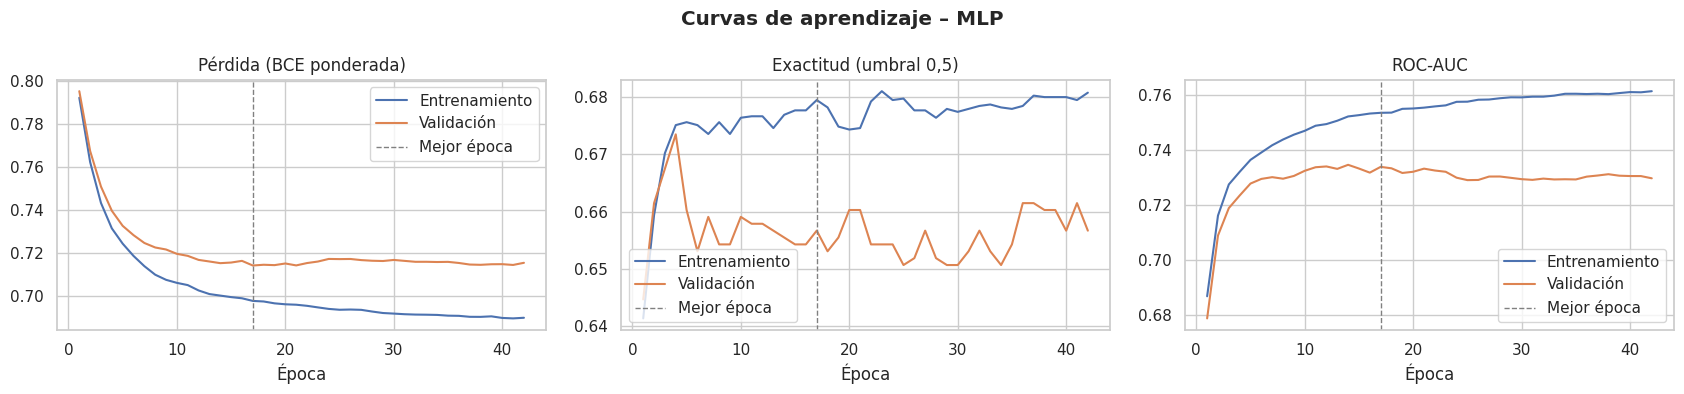

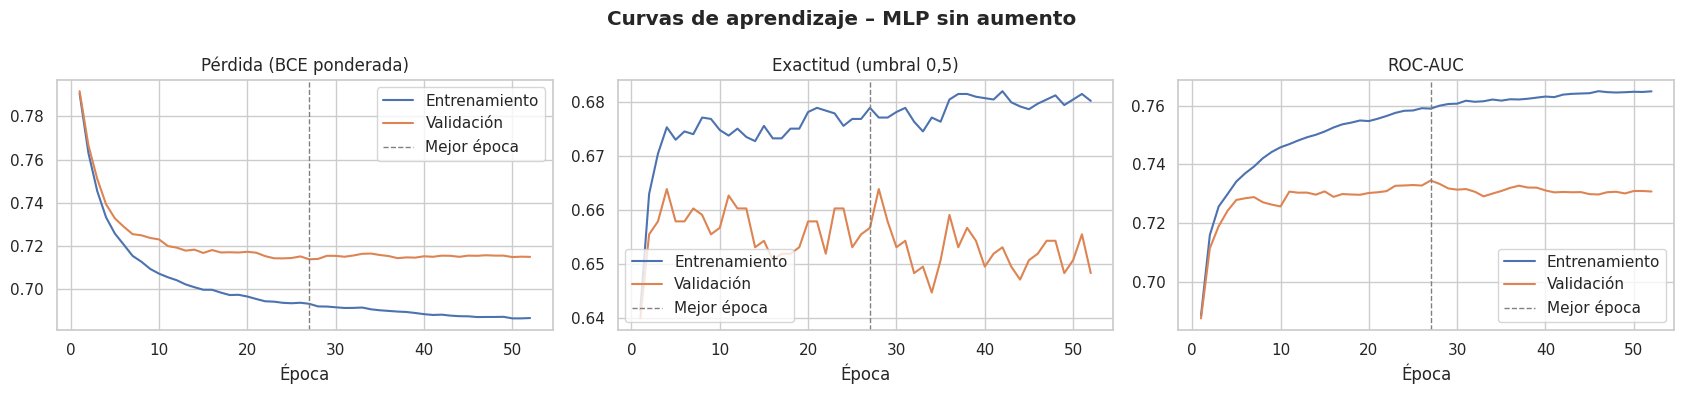

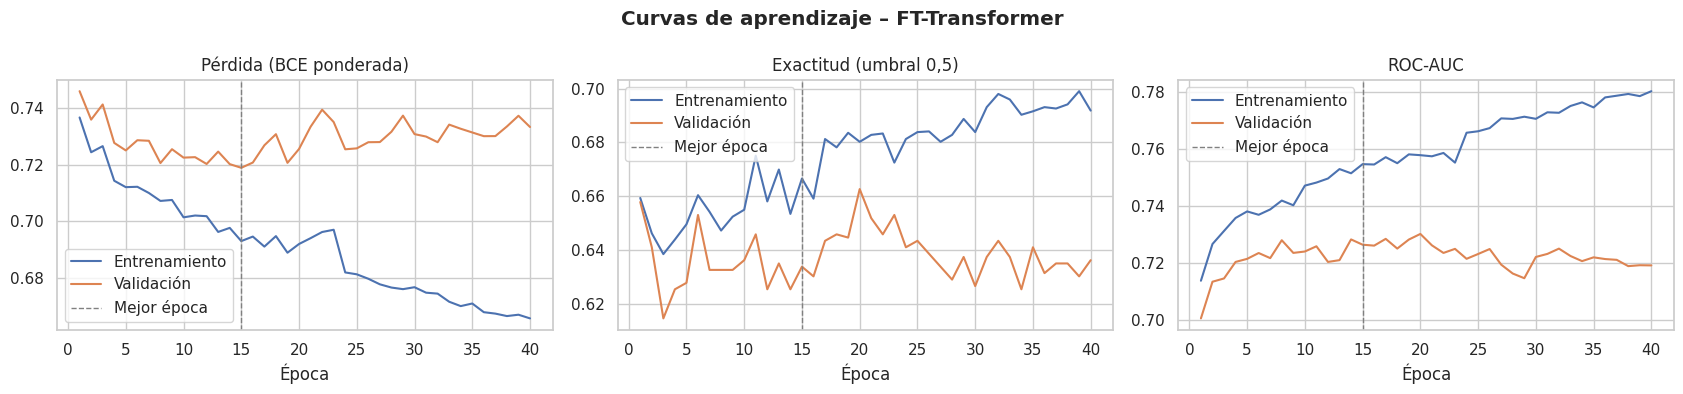

In [136]:
for nombre, hist in historiales.items():
    fig, ejes = plt.subplots(1, 3, figsize=(17, 4))
    for eje, (metrica, titulo) in zip(ejes, [("loss", "Pérdida (BCE ponderada)"),
                                              ("acc", "Exactitud (umbral 0,5)"), ("auc", "ROC-AUC")]):
        eje.plot(hist["epoca"], hist[f"{metrica}_train"], label="Entrenamiento")
        eje.plot(hist["epoca"], hist[f"{metrica}_val"], label="Validación")
        eje.axvline(mejores_epocas[nombre], color="gray", ls="--", lw=1, label="Mejor época")
        eje.set_title(titulo); eje.set_xlabel("Época"); eje.legend()
    fig.suptitle(f"Curvas de aprendizaje – {nombre}", fontweight="bold")
    plt.tight_layout()
    plt.savefig(CARPETA_ART / f"curvas_{nombre.replace(' ', '_').lower()}.png", dpi=150, bbox_inches="tight")
    plt.show()

### 4.2 Elección del umbral con validación

Para un tamizaje, el error más grave es el **falso negativo**: decirle "estás bien" a alguien con presión alta. La regla, fijada antes de ver la prueba, es: **entre los umbrales con recall ≥ 0,85 en validación, elegir el de mayor F1.** Esto corrige lo del ACA 1, donde el umbral de 0,40 se eligió mirando la prueba.

In [137]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)

RECALL_MINIMO = 0.85

def elegir_umbral(y_real, prob, recall_min=RECALL_MINIMO):
    candidatos = []
    for u in np.round(np.arange(0.05, 0.951, 0.01), 2):
        pred = (prob >= u).astype(int)
        candidatos.append({"umbral": u, "recall": recall_score(y_real, pred),
                           "f1": f1_score(y_real, pred, zero_division=0)})
    tabla = pd.DataFrame(candidatos)
    validos = tabla[tabla["recall"] >= recall_min]
    return float((validos if len(validos) else tabla).sort_values(["f1", "umbral"]).iloc[-1]["umbral"])

def metricas(y_real, prob, umbral):
    pred = (prob >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {"umbral": umbral, "accuracy": accuracy_score(y_real, pred),
            "precision": precision_score(y_real, pred, zero_division=0),
            "recall": recall_score(y_real, pred), "especificidad": vn / (vn + fp),
            "f1": f1_score(y_real, pred, zero_division=0), "auc": roc_auc_score(y_real, prob),
            "vp": int(vp), "vn": int(vn), "fp": int(fp), "fn": int(fn)}

umbrales = {n: elegir_umbral(y_val, p["val"]) for n, p in probabilidades.items()}
tabla_val = pd.DataFrame({n: metricas(y_val, p["val"], umbrales[n])
                          for n, p in probabilidades.items()}).T.astype(float)
tabla_val[["umbral", "recall", "especificidad", "f1", "auc", "fn"]].round(3)

,umbral,recall,especificidad,f1,auc,fn
Regresión logística,0.40,0.871,0.496,0.663,0.732,43.0
MLP,0.33,0.913,0.406,0.651,0.734,29.0
MLP sin aumento,0.36,0.895,0.436,0.653,0.735,35.0
FT-Transformer,0.28,0.937,0.382,0.654,0.726,21.0


### 4.3 Resultados finales en el conjunto de prueba

La prueba se usa **una sola vez**, con los umbrales ya fijados. Para el AUC se calcula un intervalo de confianza del 95 % con *bootstrap* (1.000 remuestreos), para saber si las diferencias entre modelos son reales o ruido.

In [138]:
def ic_auc(y_real, prob, n=1000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    y_real, valores = np.asarray(y_real), []
    for _ in range(n):
        i = rng.integers(0, len(y_real), len(y_real))
        if y_real[i].min() != y_real[i].max():
            valores.append(roc_auc_score(y_real[i], prob[i]))
    return np.percentile(valores, [2.5, 97.5])

filas = []
for nombre, p in probabilidades.items():
    m = metricas(y_test, p["test"], umbrales[nombre])
    m["auc_ic_inf"], m["auc_ic_sup"] = ic_auc(y_test, p["test"])
    filas.append({"modelo": nombre, **m})
tabla_test = pd.DataFrame(filas).set_index("modelo")

vista = tabla_test[["umbral", "accuracy", "precision", "recall", "especificidad", "f1", "auc", "fn"]].copy()
vista["AUC IC 95 %"] = [f"[{a:.3f} – {b:.3f}]" for a, b in tabla_test[["auc_ic_inf", "auc_ic_sup"]].values]
vista.round(3)

,umbral,accuracy,precision,recall,especificidad,f1,auc,fn,AUC IC 95 %
modelo,,,,,,,,,
Regresión logística,0.40,0.642,0.531,0.886,0.481,0.664,0.750,38,[0.720 – 0.785]
MLP,0.33,0.610,0.506,0.919,0.405,0.652,0.750,27,[0.718 – 0.781]
MLP sin aumento,0.36,0.623,0.515,0.907,0.435,0.657,0.745,31,[0.713 – 0.776]
FT-Transformer,0.28,0.595,0.496,0.949,0.361,0.651,0.746,17,[0.714 – 0.778]


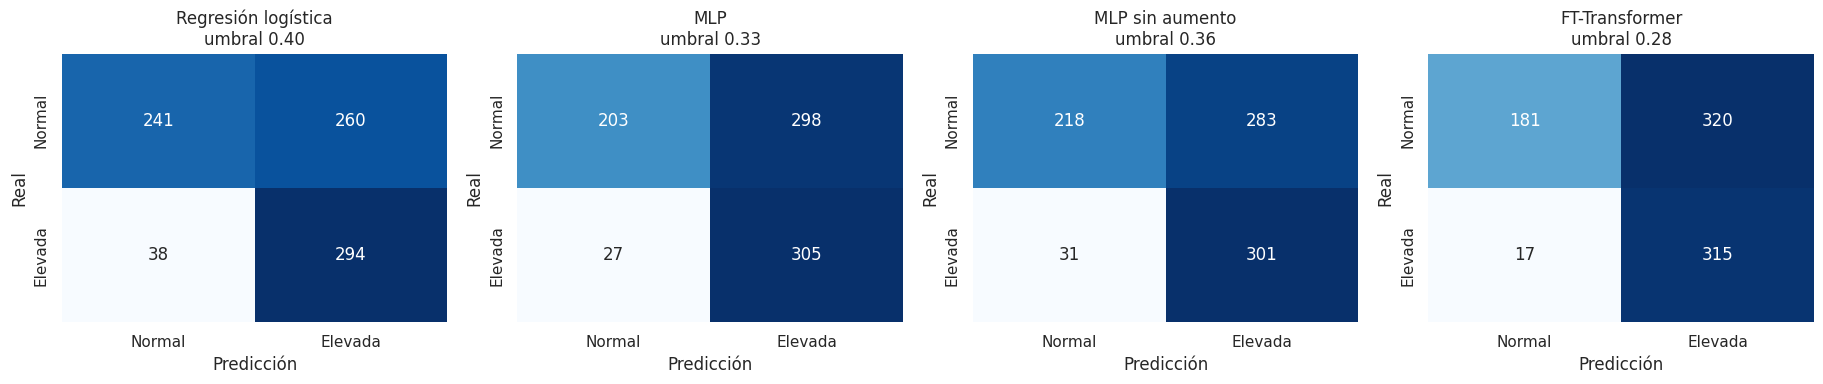

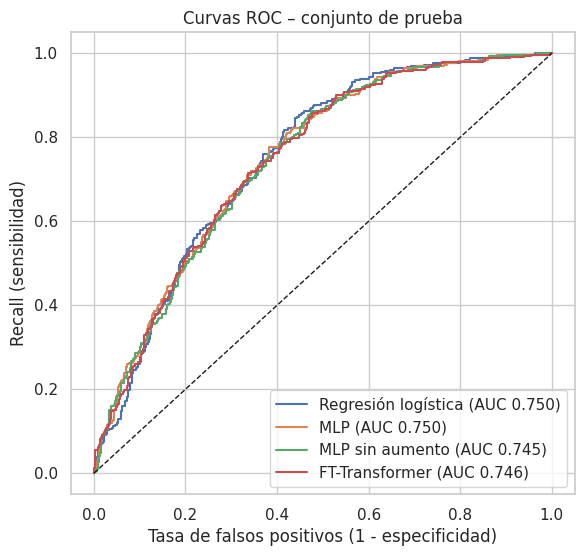

In [139]:
fig, ejes = plt.subplots(1, len(tabla_test), figsize=(4.6 * len(tabla_test), 4))
for eje, (nombre, fila) in zip(ejes, tabla_test.iterrows()):
    matriz = np.array([[fila["vn"], fila["fp"]], [fila["fn"], fila["vp"]]]).astype(int)
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=eje,
                xticklabels=["Normal", "Elevada"], yticklabels=["Normal", "Elevada"])
    eje.set_title(f"{nombre}\numbral {fila['umbral']:.2f}")
    eje.set_xlabel("Predicción"); eje.set_ylabel("Real")
plt.tight_layout()
plt.savefig(CARPETA_ART / "matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(6.5, 6))
for nombre, p in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, p["test"])
    plt.plot(fpr, tpr, label=f"{nombre} (AUC {tabla_test.loc[nombre, 'auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Tasa de falsos positivos (1 - especificidad)"); plt.ylabel("Recall (sensibilidad)")
plt.title("Curvas ROC – conjunto de prueba"); plt.legend()
plt.savefig(CARPETA_ART / "curvas_roc.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Selección del modelo para la app

Se elige la red con mayor **AUC de validación**. La prueba no interviene en la decisión. La regresión logística queda en la app como modelo de comparación.

In [140]:
candidatas = [NOMBRE_MLP, NOMBRE_FT]
MODELO_FINAL = max(candidatas, key=lambda n: tabla_val.loc[n, "auc"])
print(f"Modelo final: {MODELO_FINAL} "
      f"(AUC validación {tabla_val.loc[MODELO_FINAL, 'auc']:.3f}, umbral {umbrales[MODELO_FINAL]:.2f})")

Modelo final: MLP (AUC validación 0.734, umbral 0.33)


### 4.5 ¿Qué aprendió la red? Importancia por permutación

Se desordena una variable a la vez en la prueba y se mide cuánto cae el AUC. Si cae mucho, la red depende de esa variable. Es el mismo análisis del ACA 1, así que permite comparar si la red llegó a las mismas conclusiones.

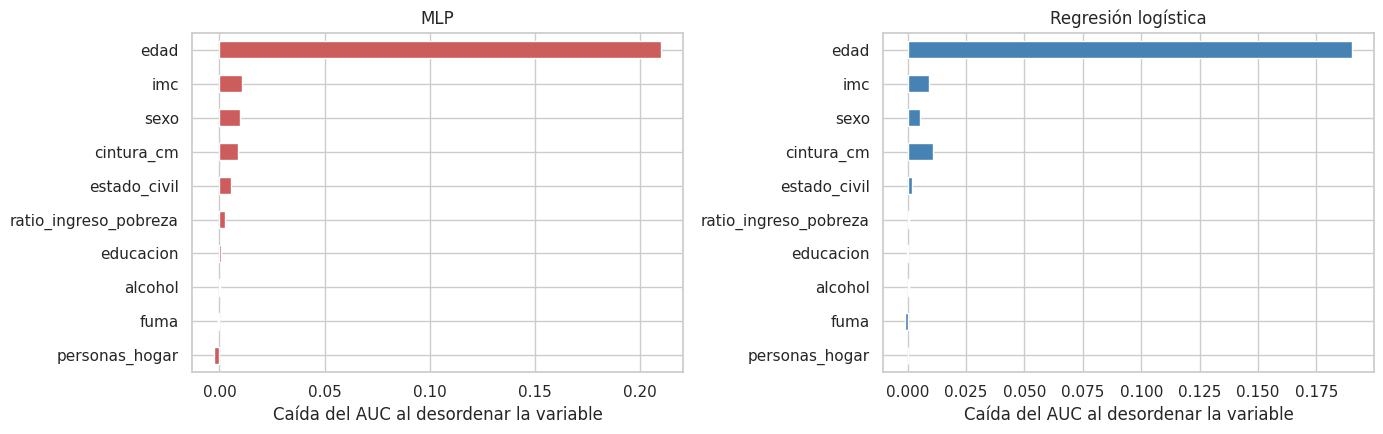

In [141]:
def importancia_permutacion(fn_proba, X_eval, y_eval, repeticiones=10, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    base = roc_auc_score(y_eval, fn_proba(X_eval))
    caidas = {}
    for col in X_eval.columns:
        valores = []
        for _ in range(repeticiones):
            X_perm = X_eval.copy()
            X_perm[col] = rng.permutation(X_perm[col].values)
            valores.append(base - roc_auc_score(y_eval, fn_proba(X_perm)))
        caidas[col] = np.mean(valores)
    return pd.Series(caidas).sort_values()

predictor_final = PredictorPresion(prep_nn, redes[MODELO_FINAL], umbrales[MODELO_FINAL], MODELO_FINAL)
imp_red = importancia_permutacion(predictor_final.predict_proba, X_test, y_test)
imp_lr = importancia_permutacion(lambda d: modelo_lr.predict_proba(d)[:, 1], X_test, y_test)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
imp_red.plot(kind="barh", ax=ejes[0], color="indianred"); ejes[0].set_title(f"{MODELO_FINAL}")
imp_lr.reindex(imp_red.index).plot(kind="barh", ax=ejes[1], color="steelblue"); ejes[1].set_title(NOMBRE_LR)
for eje in ejes:
    eje.set_xlabel("Caída del AUC al desordenar la variable")
plt.tight_layout()
plt.savefig(CARPETA_ART / "importancia_variables.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.6 Interpretación de resultados

**1. ¿La red supera a la regresión logística? No en capacidad de discriminación: la iguala.** En prueba, el MLP y la regresión logística obtuvieron el mismo AUC (0,750), y sus intervalos de confianza se traslapan casi por completo ([0,718 – 0,781] frente a [0,720 – 0,785]). Lo mismo ocurre con el FT-Transformer (0,746). La diferencia entre los modelos es menor que la incertidumbre de la medición. La explicación está en los datos: la edad sola explica casi todo el poder predictivo (sección 4.5) y su relación con el riesgo es prácticamente lineal. Una red neuronal aporta cuando hay interacciones complejas o datos no estructurados (imágenes, texto). Con 10 variables tabulares y 5.550 personas, un modelo lineal ya captura casi toda la señal disponible. Es un resultado esperado, y coincide con lo que el profesor explicó en clase: el poder de la red está en aprender funciones complejas, y esta función es sencilla.

**2. ¿Hay sobreajuste? Leve, y el early stopping lo controló.** En el MLP, la pérdida de entrenamiento siguió bajando hasta la época 42, mientras la de validación se estabilizó cerca de 0,715 desde la época 17. El early stopping conservó los pesos de esa época 17, antes de que la brecha creciera. En la mejor época la diferencia entre el AUC de entrenamiento y el de validación es pequeña (≈ 0,75 frente a 0,73). El FT-Transformer muestra una tendencia más clara a memorizar: después de la época 15 la pérdida de validación sube y oscila, mientras la de entrenamiento sigue bajando y su AUC de entrenamiento llega a 0,78 con la validación estancada en 0,72. La búsqueda de hiperparámetros apunta en la misma dirección: ganó la red más pequeña (1.550 parámetros) y el dropout de 0,3 superó al de 0,1 en las tres profundidades. Más regularización funcionó mejor, igual que la C = 0,01 en la regresión logística.

**3. ¿Ayudó el aumento de datos? Regularizó un poco, pero no mejoró la discriminación.** Con ruido, la brecha de pérdida entre validación y entrenamiento fue de 0,0164, frente a 0,0207 sin ruido: alrededor de un 20 % menos de sobreajuste. El AUC de validación fue prácticamente igual (0,7339 frente a 0,7345). En prueba, la versión con ruido obtuvo un AUC un poco mayor (0,750 frente a 0,745) y 4 falsos negativos menos (27 frente a 31). Son diferencias pequeñas, dentro del margen de error. El ruido cumple su papel de regularizador, pero no es un factor decisivo con estos datos.

**4. ¿El FT-Transformer encontró interacciones útiles? No.** Su AUC de validación (0,726) fue menor que el del MLP (0,734), y en prueba quedó en 0,746, sin diferencia real. Tiene casi 12 veces más parámetros (18.433 frente a 1.550). La autoatención necesita muchos más datos para justificar esa capacidad, y aquí terminó aprendiendo ruido del entrenamiento (punto 2). Que no supere al MLP confirma que en estos datos no hay interacciones complejas entre variables que valga la pena modelar.

**5. Falsos negativos: el modelo final deja pasar a menos personas, pero hay que leerlo con cuidado.** En prueba hay unas 332 personas con presión elevada. El MLP no detectó a 27 (8,1 %) y la regresión logística a 38 (11,4 %). En el ACA 1 se escapaba el 11,5 % (51 de 443), con un umbral elegido mirando la prueba. Ahora el umbral se eligió con validación, así que el resultado es más honesto. Sin embargo, la mejora frente a la regresión logística **no viene de que la red ordene mejor el riesgo** (el AUC es igual), sino de su umbral más bajo (0,33 frente a 0,40). El costo es la especificidad: baja de 0,481 a 0,405, lo que equivale a unas 38 falsas alarmas más entre las 501 personas sanas. Para un tamizaje ese intercambio es aceptable: una medición de presión de más es barata, mientras que una hipertensión no detectada no lo es. El FT-Transformer lleva este intercambio al extremo: 17 falsos negativos, pero la especificidad más baja (0,361).

**6. Variables: la red llegó a las mismas conclusiones que el ACA 1.** En la importancia por permutación, la edad domina en los dos modelos: desordenarla hace caer el AUC unos 0,21 en el MLP y 0,19 en la regresión logística. Le siguen, muy por detrás, el IMC, el sexo y la cintura. El alcohol, el tabaco y las personas en el hogar no aportan nada (caída ≈ 0). Esto sugiere que la asociación del tabaco vista en el EDA se explica por otras variables, probablemente la edad. El MLP da un pequeño peso al estado civil y al ingreso, que la regresión logística ignora. Esa es la única señal de que la red encontró relaciones no lineales, y su efecto es marginal. Que dos modelos tan distintos coincidan hace más confiables las conclusiones y reduce el problema de "caja negra" de la red.

---
# 5. Exportación para Streamlit

Se guarda todo lo que necesita la app:

- **Pesos de las redes** (`.pt`), el preprocesador y la regresión logística (`.joblib`).
- **`config.json`**, con arquitectura, hiperparámetros, umbrales y categorías.
- **Tablas en SQLite:** métricas, curvas de entrenamiento, puntos de la curva ROC y la tabla vacía donde la app registrará cada predicción.
- **`requirements.txt`**, con las versiones exactas usadas aquí.

In [142]:
import joblib

joblib.dump(prep_nn, CARPETA_ART / "preprocesador_nn.joblib")
joblib.dump({"modelo": modelo_lr, "umbral": umbrales[NOMBRE_LR]}, CARPETA_ART / "regresion_logistica.joblib")

modelos_app = {}
for nombre in [MODELO_FINAL] + [n for n in candidatas if n != MODELO_FINAL]:
    archivo = f"{configuraciones[nombre]['tipo']}.pt"
    torch.save(redes[nombre].state_dict(), CARPETA_ART / archivo)
    modelos_app[nombre] = {"tipo": configuraciones[nombre]["tipo"], "hiper": configuraciones[nombre]["hiper"],
                           "archivo": archivo, "umbral": umbrales[nombre]}

shutil.copy("modelos_nn.py", CARPETA_APP / "modelos_nn.py")

PosixPath('app_presion/modelos_nn.py')

In [143]:
import sklearn

config = {
    "modelo_principal": MODELO_FINAL,
    "modelos": modelos_app,
    "preprocesador": "preprocesador_nn.joblib",
    "regresion_logistica": "regresion_logistica.joblib",
    "cardinalidades": cardinalidades,
    "categorias": categorias,
    "recall_minimo": RECALL_MINIMO,
    "registros_entrenamiento": int(len(X_train)),
}
(CARPETA_ART / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

# --- Métricas, curvas y ROC en SQLite  ---
fecha = pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")
met = pd.concat([tabla_val.assign(conjunto="validacion"), tabla_test.assign(conjunto="prueba")])
met = met.rename_axis("modelo").reset_index().assign(fecha=fecha)
met.to_sql("metricas_modelos", conexion, if_exists="replace", index=False)

pd.concat([h.assign(modelo=n, mejor_epoca=mejores_epocas[n]) for n, h in historiales.items()]) \
  .to_sql("historial_entrenamiento", conexion, if_exists="replace", index=False)

filas_roc = []
for nombre, p in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, p["test"])
    filas_roc.append(pd.DataFrame({"modelo": nombre, "fpr": fpr, "tpr": tpr}))
pd.concat(filas_roc).to_sql("curva_roc", conexion, if_exists="replace", index=False)

cur.executescript("""
DROP TABLE IF EXISTS predicciones;
CREATE TABLE predicciones (
    id                    INTEGER PRIMARY KEY AUTOINCREMENT,
    fecha                 TEXT NOT NULL,
    edad INTEGER, sexo TEXT, imc REAL, cintura_cm REAL, fuma TEXT, alcohol TEXT,
    educacion TEXT, estado_civil TEXT, personas_hogar INTEGER, ratio_ingreso_pobreza REAL,
    modelo                TEXT NOT NULL,
    probabilidad          REAL NOT NULL,
    umbral                REAL NOT NULL,
    resultado             TEXT NOT NULL,
    probabilidad_lr       REAL
);
""")
conexion.commit()

# --- requirements.txt con las versiones de este entorno ---
version_torch = VERSION_TORCH.split("+")[0]
(CARPETA_APP / "requirements.txt").write_text(
    "--extra-index-url https://download.pytorch.org/whl/cpu\n"
    f"torch=={version_torch}+cpu\n"
    f"streamlit>=1.40\n"
    f"scikit-learn=={sklearn.__version__}\n"
    f"pandas=={pd.__version__}\n"
    f"numpy=={np.__version__}\n"
    f"joblib=={joblib.__version__}\n"
    f"matplotlib>=3.8\n", encoding="utf-8")

print((CARPETA_APP / "requirements.txt").read_text())
consulta("SELECT name AS tabla_o_vista, type FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name")

--extra-index-url https://download.pytorch.org/whl/cpu
torch==2.14.1+cpu
streamlit>=1.40
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0
matplotlib>=3.8



,tabla_o_vista,type
0,curva_roc,table
1,datos_limpios,table
2,diccionario,table
3,historial_entrenamiento,table
4,metricas_modelos,table
5,nhanes_crudo,table
6,particiones,table
7,predicciones,table
8,sqlite_sequence,table
9,v_presion,view


### 5.1 Prueba de extremo a extremo: cargar y predecir como lo hará la app

Se cargan los artefactos desde disco con la misma función que usa `app.py`, se predice un paciente de ejemplo y se registra en la tabla `predicciones` (`INSERT`). Así se comprueba que la app funcionará con estos archivos.

In [144]:
from modelos_nn import cargar_predictores

predictores_app, config_app = cargar_predictores(CARPETA_ART)
lr_app = joblib.load(CARPETA_ART / "regresion_logistica.joblib")

paciente = pd.DataFrame([{"edad": 55, "imc": 31.0, "cintura_cm": 104.0, "ratio_ingreso_pobreza": 2.5,
                          "personas_hogar": 3, "sexo": "Hombre", "fuma": "Sí", "alcohol": "Sí",
                          "educacion": "Bachiller", "estado_civil": "Casado(a)"}])
pred = predictores_app[config_app["modelo_principal"]]
prob = float(pred.predict_proba(paciente)[0])
prob_lr = float(lr_app["modelo"].predict_proba(paciente[VARIABLES])[:, 1][0])

# La red cargada desde disco debe dar lo mismo que la red en memoria
assert np.allclose(pred.predict_proba(X_test), predictor_final.predict_proba(X_test), atol=1e-5)

cur.execute("""
INSERT INTO predicciones (fecha, edad, sexo, imc, cintura_cm, fuma, alcohol, educacion, estado_civil,
                          personas_hogar, ratio_ingreso_pobreza, modelo, probabilidad, umbral,
                          resultado, probabilidad_lr)
VALUES (datetime('now', 'localtime'), ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
""", (*[a_python(paciente.iloc[0][c]) for c in ["edad", "sexo", "imc", "cintura_cm", "fuma", "alcohol",
                                                "educacion", "estado_civil", "personas_hogar",
                                                "ratio_ingreso_pobreza"]],
      pred.nombre, prob, pred.umbral, "Elevada" if prob >= pred.umbral else "Normal", prob_lr))
conexion.commit()
print(consulta("SELECT id, fecha, edad, sexo, modelo, ROUND(probabilidad, 3) AS prob, resultado FROM predicciones"))

# Se borra la fila de prueba para entregar la tabla vacía
cur.execute("DELETE FROM predicciones"); cur.execute("DELETE FROM sqlite_sequence WHERE name = 'predicciones'")
conexion.commit()

   id                fecha  edad    sexo modelo   prob resultado
0   1  2026-11-15 18:48:05    55  Hombre    MLP  0.555   Elevada


In [145]:
# Empaquetar la carpeta de la app (app.py y README.md se agregan desde el paquete entregado)
conexion.close()
archivo_zip = shutil.make_archive("app_presion", "zip", ".", "app_presion")
print("Generado:", archivo_zip)
for ruta in sorted(CARPETA_APP.rglob("*")):
    if ruta.is_file():
        print(f"  {ruta}  ({ruta.stat().st_size / 1024:.0f} KB)")

if EN_COLAB:
    from google.colab import files
    files.download(archivo_zip)

Generado: /content/app_presion.zip
  app_presion/artefactos/config.json  (1 KB)
  app_presion/artefactos/curvas_ft-transformer.png  (180 KB)
  app_presion/artefactos/curvas_mlp.png  (150 KB)
  app_presion/artefactos/curvas_mlp_sin_aumento.png  (161 KB)
  app_presion/artefactos/curvas_roc.png  (95 KB)
  app_presion/artefactos/eda_prevalencia.png  (126 KB)
  app_presion/artefactos/ft.pt  (82 KB)
  app_presion/artefactos/importancia_variables.png  (61 KB)
  app_presion/artefactos/matrices_confusion.png  (57 KB)
  app_presion/artefactos/mlp.pt  (12 KB)
  app_presion/artefactos/preprocesador_nn.joblib  (176 KB)
  app_presion/artefactos/regresion_logistica.joblib  (177 KB)
  app_presion/modelos_nn.py  (5 KB)
  app_presion/nhanes_presion.db  (1364 KB)
  app_presion/requirements.txt  (0 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Conclusiones


1. **Datos y SQL:** la gestión en SQLite reprodujo exactamente la limpieza del ACA 1: 5.550 registros y 39,9 % de presión elevada, verificado fila por fila en la sección 1.5. Además dejó trazables el diccionario de datos, las particiones, las métricas, las curvas de entrenamiento y las predicciones de la app, todo dentro de un solo archivo que viaja con la aplicación.
2. **Arquitecturas:** se entrenaron un MLP profundo con embeddings y un FT-Transformer. El MLP (2 capas ocultas de 32 y 16 neuronas, dropout 0,3, 1.550 parámetros) obtuvo el mejor AUC de validación (0,734) y es el modelo desplegado en la app. En prueba alcanzó un AUC de 0,750 [IC 95 %: 0,718 – 0,781], un recall de 0,919 y 27 falsos negativos (8,1 % de los casos), con un umbral de 0,33 elegido en validación, sin mirar la prueba.
3. **Red vs. modelo clásico:** frente a la regresión logística (AUC 0,750 [0,720 – 0,785]), la red **igualó** la capacidad de discriminación; los intervalos de confianza se traslapan casi por completo. Esto indica que, con 10 variables tabulares donde la edad explica casi todo el riesgo, la relación es prácticamente lineal y una red neuronal no tiene patrones complejos que aprovechar. La red sí permitió un punto de operación más sensible (11 falsos negativos menos), a costa de más falsas alarmas.
4. **Aumento de datos:** el ruido gaussiano redujo la brecha entre entrenamiento y validación en cerca de un 20 % (0,0164 frente a 0,0207), sin cambiar el AUC. Funcionó como regularizador, junto con el dropout, el weight decay y el early stopping. El FT-Transformer, con 12 veces más parámetros, mostró más sobreajuste y no superó al MLP.
5. **Interpretación:** la red coincide con el ACA 1 y con la regresión logística en que la edad es el factor dominante, seguida del IMC, el sexo y la cintura. El tabaco y el alcohol no aportan una vez se consideran las demás variables.
6. **Limitaciones:** son datos de EE. UU. (2015-2016) con topes en edad (80), ingreso (5) y personas en el hogar (7). La presión se tomó en una sola visita, y la especificidad del modelo es baja (≈ 0,40): de cada 10 personas sanas, unas 6 recibirían la recomendación de medirse. La herramienta es un tamizaje, no un diagnóstico.
7. **Trabajo futuro:** validar el modelo con datos colombianos; incluir variables que hoy no están, como antecedentes familiares, actividad física o consumo de sal, que podrían darle a la red patrones más complejos que aprovechar; y calibrar las probabilidades para que el porcentaje que muestra la app sea más interpretable.
---
## Referencias

Centers for Disease Control and Prevention. (2017). *National Health and Nutrition Examination Survey 2015-2016* [Conjunto de datos]. National Center for Health Statistics. https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?BeginYear=2015

Gorishniy, Y., Rubachev, I., Khrulkov, V., & Babenko, A. (2021). Revisiting deep learning models for tabular data. *Advances in Neural Information Processing Systems, 34*, 18932–18943.

Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. *Proceedings of the 32nd International Conference on Machine Learning*, 448–456.

Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. *International Conference on Learning Representations*.

Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., ... & Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(1), 1929–1958.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*.

Whelton, P. K., Carey, R. M., Aronow, W. S., et al. (2018). 2017 ACC/AHA/AAPA/ABC/ACPM/AGS/APhA/ASH/ASPC/NMA/PCNA guideline for the prevention, detection, evaluation, and management of high blood pressure in adults. *Hypertension, 71*(6), e13–e115. https://doi.org/10.1161/HYP.0000000000000065